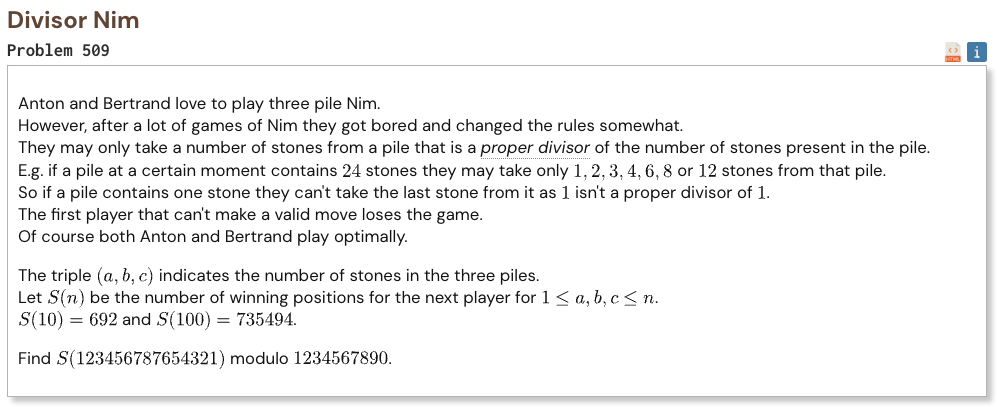

## Initial approach

- the Grundy value of a pile depends only on how many times its size is divisible by 2
- count how many numbers up to the limit have each possible Grundy value
- a three pile position is losing when the xor of the three Grundy values is zero
- for each pair of Grundy values, the third value is fixed by xor
- multiply their frequencies to count all losing triples
- subtract the losing triples from all possible triples
- take the result modulo 1234567890

In [1]:
%%time

N = 123456787654321
MOD = 1234567890

counts = []
k = 0

while (1 << k) <= N:
    current = (
        N // (1 << k)
        - N // (1 << (k + 1))
    )

    counts.append(current)
    k += 1

losing = 0

for i in range(len(counts)):
    for j in range(len(counts)):
        third = i ^ j

        if third < len(counts):
            losing += (
                counts[i]
                * counts[j]
                * counts[third]
            )

result = (
    pow(N, 3, MOD)
    - losing % MOD
) % MOD

print("Result:", result)

Result: 151725678
CPU times: user 841 μs, sys: 44 μs, total: 885 μs
Wall time: 901 μs
